# 4. Fit and evaluate the cyber-log baseline

This notebook establishes M0 using the technical features from Notebook 2 and the chronological split saved by Notebook 3.

It fits Isolation Forest and a reconstruction autoencoder on training data, then forms their percentile-rank ensemble. The recorded detector-family selection uses validation average precision under the as-run labels.

**Outputs:** `scores_m0.parquet`, fitted model objects, `m0_feature_list.json`, `threshold_policy.json`, `modelling_utils.py`, evaluation tables and figures. Notebook 5 reuses the baseline scores and shared modelling code.

Labels are excluded from detector inputs. They are used for the benign-training check, validation-based selection and evaluation.

This notebook contains baseline test evaluation. Its cell order does not establish that the test partition was never inspected earlier; the dissertation records the M0-only preview and later validation-label correction. The saved policy and scores remain the historical baseline for the primary comparison.

*Documentation copy, 8 November 2026. Notes edited for clarity; code, saved outputs and execution metadata are unchanged. This copy has not been rerun.*


In [1]:
# ============================================================
# 0. Setup — load features + FROZEN split; build M0 feature list
# ============================================================
import os, glob, json, random, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED)
warnings.filterwarnings("ignore")
WORK = "/kaggle/working"
T0 = time.time()

f_hits = glob.glob("/kaggle/input/**/features_cyberlog.parquet", recursive=True)
s_hits = glob.glob("/kaggle/input/**/split_definition.json", recursive=True)
assert f_hits, "Notebook 2 output not attached (features_cyberlog.parquet)"
assert s_hits, ("Notebook 3 output not attached (split_definition.json). "
                "NB4 IMPORTS the frozen split — it never recomputes it.")
print("features:", f_hits[0])
print("split   :", s_hits[0])

feats = pd.read_parquet(f_hits[0])
feats["user"] = feats["user"].astype(str)
feats["day"]  = pd.to_datetime(feats["day"])
SPLIT = json.load(open(s_hits[0]))
print("frozen split:", {k: v for k, v in SPLIT.items() if k != "rationale"})

# --- label column: used for EVALUATION ONLY anywhere in this notebook ---
LABEL_CANDIDATES = ["label", "is_malicious", "malicious", "y"]
LABEL_COL = next((c for c in LABEL_CANDIDATES if c in feats.columns), None)
assert LABEL_COL is not None, (
    f"No label column found among {LABEL_CANDIDATES}.\n"
    f"Available columns: {sorted(feats.columns)}\n"
    "Add NB2's label column name to LABEL_CANDIDATES above.")
print(f"label column: '{LABEL_COL}' | positive user-days: {int(feats[LABEL_COL].sum())}")

# --- M0 feature list = every numeric NB2 column except ids/labels/partitions ---
NON_FEATURES = {"user", "day", "month", "partition", LABEL_COL,
                "user_is_insider", "designated_insider", "scenario"}
FEATURES = [c for c in feats.columns
            if c not in NON_FEATURES and pd.api.types.is_numeric_dtype(feats[c])]
assert len(FEATURES) >= 20, (
    f"Only {len(FEATURES)} numeric feature columns found — check NB2 output.\n"
    f"Found: {FEATURES}")
assert LABEL_COL not in FEATURES and "user_is_insider" not in FEATURES
json.dump(FEATURES, open(f"{WORK}/m0_feature_list.json", "w"), indent=1)
print(f"M0 feature list: {len(FEATURES)} columns (saved m0_feature_list.json)")

# --- NaN / inf audit (filled with 0 at matrix build; see markdown rationale) ---
na = feats[FEATURES].isna().sum().sort_values(ascending=False)
na = na[na > 0]
print(f"\ncolumns containing NaN (-> 0 in model matrix): {len(na)}")
print(na.head(10).to_string() if len(na) else "  none")
arr_probe = feats[FEATURES].to_numpy(dtype="float32", na_value=0.0)
print("inf cells (-> 0 in model matrix):", int(np.isinf(arr_probe).sum()))
del arr_probe

features: /kaggle/input/notebooks/thandondhlovu10/2-feature-engineering/features_cyberlog.parquet
split   : /kaggle/input/notebooks/thandondhlovu10/3-synthetic-organisational-bi/split_definition.json
frozen split: {'train_start': '2010-01-01', 'train_end': '2010-07-31', 'val_start': '2010-08-01', 'val_end': '2010-12-31', 'test_start': '2011-01-01', 'test_end': '2011-05-31', 'seed': 42}
label column: 'label' | positive user-days: 78
M0 feature list: 41 columns (saved m0_feature_list.json)

columns containing NaN (-> 0 in model matrix): 0
  none
inf cells (-> 0 in model matrix): 0


## 1. Load and check the saved split

Use `split_definition.json` from Notebook 3 rather than choosing new boundaries. Observations outside the inclusive windows are excluded from modelling.

The training partition must contain no labelled-positive days. Validation and test counts are compared with the as-run values of 40 and 38. The later corrected validation count belongs to the sensitivity analysis, not a silent replacement of this historical input.


In [2]:
# ============================================================
# 1. Apply the frozen split (imported — never recomputed)
# ============================================================
d = feats["day"]
feats["partition"] = np.select(
    [(d >= SPLIT["train_start"]) & (d <= SPLIT["train_end"]),
     (d >= SPLIT["val_start"])   & (d <= SPLIT["val_end"]),
     (d >= SPLIT["test_start"])  & (d <= SPLIT["test_end"])],
    ["train", "val", "test"], default="drop")
print(feats["partition"].value_counts())

lab = feats.groupby("partition")[LABEL_COL].sum().astype(int)
print("\nmalicious user-days per partition:")
print(lab.to_string())

# HARD GATE: the entire anomaly-detection framing rests on benign-only training.
assert int(lab.get("train", 0)) == 0, (
    "Training window contains malicious user-days — the benign-only training "
    "premise is violated. Do NOT proceed; inspect NB2 labels / split_definition.json.")

# Soft check against the counts confirmed by the NB2 run (handoff §4).
EXPECTED = {"val": 40, "test": 38}
for p, e in EXPECTED.items():
    got = int(lab.get(p, 0))
    if got != e:
        print(f"WARNING: partition '{p}' has {got} malicious user-days; the NB2 run "
              f"recorded {e}. Verify NB2 labelling before trusting any results.")

feats = feats[feats["partition"] != "drop"].reset_index(drop=True)
MASK = {p: (feats["partition"] == p).to_numpy() for p in ("train", "val", "test")}
print(f"\nrows after dropping out-of-window user-days: {len(feats):,}")
print(f"train users: {feats.loc[MASK['train'], 'user'].nunique():,} | "
      f"val users: {feats.loc[MASK['val'], 'user'].nunique():,} | "
      f"test users: {feats.loc[MASK['test'], 'user'].nunique():,}")

partition
train    592378
val      406070
test     395549
drop         13
Name: count, dtype: int64

malicious user-days per partition:
partition
drop      0
test     38
train     0
val      40

rows after dropping out-of-window user-days: 1,393,997
train users: 4,000 | val users: 3,867 | test users: 3,741


## 2. Save the shared modelling functions

This cell writes and imports `modelling_utils.py`. Notebook 5 imports that saved module for the common matrix preparation, fitting, scoring, alert selection and evaluation primitives. Additional paired-analysis helpers are defined in Notebook 5 itself.

A shared implementation makes the computational path traceable. It does not make the feature representations identical or separate information effects from changes in dimensionality.


In [3]:
# ============================================================
# 2. Shared modelling utilities — written to disk, then imported
#    NB5 must import THIS FILE from NB4's attached output, so all
#    configurations M0-M3 run byte-identical logic.
# ============================================================
UTILS_SRC = r'''
"""modelling_utils.py — shared modelling & evaluation utilities for NB4 (M0) and NB5 (M0-M3).

Written to /kaggle/working by Notebook 4. Notebook 5 MUST import this file from
NB4's attached output (importlib.spec_from_file_location), never re-implement it,
so that all four configurations share byte-identical fitting/scoring/evaluation
logic. Any change here is a change for every model.

Design constants (documented in NB4 markdown):
- Detectors: IsolationForest (300 trees, 2048-row subsampling) and an autoencoder
  implemented as a fully-connected MLP (d -> 32 -> 8 -> 32 -> d) trained to
  reconstruct its (benign) input; anomaly score = per-row MSE reconstruction error.
  sklearn is used instead of TF/Keras for CPU determinism and version stability
  on Kaggle (random_state pins the AE; no GPU nondeterminism).
- Features are RobustScaler-scaled (fit on train only, by the caller passing X_train);
  the AE additionally sees values clipped to +-AE_CLIP so single extreme cells cannot
  dominate the MSE loss. The IsolationForest sees the unclipped scaled matrix.
- 'ens' = mean of the two detectors' percentile ranks (computed over whatever matrix
  is scored in one call; monotone within any evaluation window, so budget alerts are
  unaffected by the rank base).
- Alert budget: top k% of user-days by score WITHIN the evaluation window (rank-based,
  deterministic mergesort tie-breaking).
- Cluster bootstrap: resampling is BY USER (the pre-registered clustering unit),
  stratified into users with >=1 malicious day vs none, alert set held fixed.
"""
import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import IsolationForest
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import roc_auc_score, average_precision_score

SEED_DEFAULT = 42
AE_CLIP = 10.0


def prepare_matrix(df, feature_cols):
    """float32 matrix; NaN and +-inf -> 0 (documented: NaN z-scores in a user's first
    active week mean 'no deviation history'; missing channel counts mean no activity)."""
    X = df[feature_cols].to_numpy(dtype="float32", na_value=0.0)
    return np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)


def fit_detectors(X_train, seed=SEED_DEFAULT, ae_hidden=(32, 8, 32),
                  if_estimators=300, if_max_samples=2048, ae_max_iter=40):
    """Fit scaler + both detectors on the TRAIN matrix only (caller enforces)."""
    scaler = RobustScaler().fit(X_train)
    Xs = scaler.transform(X_train)
    Xc = np.clip(Xs, -AE_CLIP, AE_CLIP)
    iforest = IsolationForest(
        n_estimators=if_estimators,
        max_samples=min(if_max_samples, len(X_train)),
        random_state=seed, n_jobs=-1).fit(Xs)
    ae = MLPRegressor(
        hidden_layer_sizes=ae_hidden, activation="relu", solver="adam",
        batch_size=min(1024, len(X_train)), learning_rate_init=1e-3,
        max_iter=ae_max_iter, early_stopping=True, validation_fraction=0.1,
        n_iter_no_change=5, random_state=seed)
    ae.fit(Xc, Xc)
    return {"scaler": scaler, "iforest": iforest, "ae": ae}


def score_detectors(models, X, chunk=200_000):
    """Score a matrix with both detectors + rank ensemble. Higher = more anomalous.
    Scoring is CHUNKED and kept in float32 so peak memory stays bounded regardless
    of matrix size (RobustScaler.transform otherwise upcasts the full matrix to
    float64; ~1.4M x 41 would transiently need several GB). Chunking changes no
    numbers: each row's scores are independent of the chunking."""
    n = len(X)
    s_if = np.empty(n, dtype="float32")
    s_ae = np.empty(n, dtype="float32")
    for i in range(0, n, chunk):
        Xs = models["scaler"].transform(X[i:i + chunk]).astype("float32")
        s_if[i:i + chunk] = -models["iforest"].score_samples(Xs)
        np.clip(Xs, -AE_CLIP, AE_CLIP, out=Xs)
        recon = models["ae"].predict(Xs)
        s_ae[i:i + chunk] = ((Xs - recon) ** 2).mean(axis=1)
        del Xs, recon
    r_if = pd.Series(s_if).rank(pct=True).to_numpy()
    r_ae = pd.Series(s_ae).rank(pct=True).to_numpy()
    return {"if": s_if, "ae": s_ae, "ens": ((r_if + r_ae) / 2).astype("float32")}


def alerts_at_budget(scores, k_pct):
    """Boolean mask alerting the top k% of rows by score (>=1 alert guaranteed)."""
    n = len(scores)
    n_alert = max(1, int(np.floor(n * k_pct / 100.0)))
    order = np.argsort(-np.asarray(scores), kind="mergesort")
    alert = np.zeros(n, dtype=bool)
    alert[order[:n_alert]] = True
    return alert


def counts(y, alert):
    y = np.asarray(y).astype(bool)
    a = np.asarray(alert).astype(bool)
    return (int((y & a).sum()), int((~y & a).sum()),
            int((y & ~a).sum()), int((~y & ~a).sum()))


def metrics_from_counts(tp, fp, fn, tn):
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    fpr = fp / (fp + tn) if (fp + tn) else 0.0
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    return {"precision": prec, "recall": rec, "fpr": fpr, "f1": f1,
            "tp": tp, "fp": fp, "fn": fn, "tn": tn}


def budget_grid(y, scores, k_grid):
    rows = []
    for k in k_grid:
        a = alerts_at_budget(scores, k)
        m = metrics_from_counts(*counts(y, a))
        m["k_pct"] = k
        m["n_alerts"] = int(a.sum())
        rows.append(m)
    return pd.DataFrame(rows)


def _user_count_table(users, y, alert):
    df = pd.DataFrame({"user": users,
                       "y": np.asarray(y).astype(bool),
                       "a": np.asarray(alert).astype(bool)})
    return (df.assign(tp=df.y & df.a, fp=~df.y & df.a,
                      fn=df.y & ~df.a, tn=~df.y & ~df.a)
              .groupby("user")[["tp", "fp", "fn", "tn"]].sum())


def cluster_bootstrap_counts(users, y, alert, n_boot=1000, seed=SEED_DEFAULT):
    """Stratified cluster-by-user bootstrap of budget metrics, alert set held fixed.
    Returns {metric: (ci_lo, ci_hi)} at 2.5/97.5 percentiles."""
    agg = _user_count_table(users, y, alert)
    is_pos = (agg["tp"] + agg["fn"]) > 0
    pos = agg[is_pos].to_numpy(dtype="int64")
    ben = agg[~is_pos].to_numpy(dtype="int64")
    rng = np.random.default_rng(seed)
    out = {"precision": [], "recall": [], "fpr": [], "f1": []}
    for _ in range(n_boot):
        s = np.zeros(4, dtype="int64")
        if len(pos):
            s += pos[rng.integers(0, len(pos), len(pos))].sum(axis=0)
        if len(ben):
            s += ben[rng.integers(0, len(ben), len(ben))].sum(axis=0)
        m = metrics_from_counts(*[int(v) for v in s])
        for k in out:
            out[k].append(m[k])
    return {k: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5)))
            for k, v in out.items()}


def cluster_bootstrap_auc(users, y, scores, n_boot=200, seed=SEED_DEFAULT):
    """Stratified cluster-by-user bootstrap of ROC-AUC / PR-AUC (re-ranked per resample)."""
    df = pd.DataFrame({"user": users, "y": np.asarray(y).astype(int),
                       "s": np.asarray(scores)})
    groups = {u: (g["y"].to_numpy(), g["s"].to_numpy())
              for u, g in df.groupby("user")}
    upos = np.array([u for u, (yy, _) in groups.items() if yy.any()])
    uben = np.array([u for u, (yy, _) in groups.items() if not yy.any()])
    rng = np.random.default_rng(seed)
    roc, pr = [], []
    for _ in range(n_boot):
        chosen = list(rng.choice(upos, len(upos))) + list(rng.choice(uben, len(uben)))
        yy = np.concatenate([groups[u][0] for u in chosen])
        ss = np.concatenate([groups[u][1] for u in chosen])
        roc.append(roc_auc_score(yy, ss))
        pr.append(average_precision_score(yy, ss))
    pct = lambda v: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5)))
    return {"roc_auc": pct(roc), "pr_auc": pct(pr)}
'''

with open(f"{WORK}/modelling_utils.py", "w") as fh:
    fh.write(UTILS_SRC)

import importlib.util
spec = importlib.util.spec_from_file_location(
    "modelling_utils", f"{WORK}/modelling_utils.py")
mu = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mu)

print("modelling_utils.py written and imported. Public API:")
print(" ", ", ".join(sorted(n for n in dir(mu) if not n.startswith("_")
                            and callable(getattr(mu, n)))))

modelling_utils.py written and imported. Public API:
  IsolationForest, MLPRegressor, RobustScaler, alerts_at_budget, average_precision_score, budget_grid, cluster_bootstrap_auc, cluster_bootstrap_counts, counts, fit_detectors, metrics_from_counts, prepare_matrix, roc_auc_score, score_detectors


## 3. Fit the candidate detectors

Each fitted object uses training rows only. The common scaler is a training-fitted `RobustScaler`.

- **Isolation Forest:** 300 trees and a maximum sample size of 2,048. Negated `score_samples` values make larger scores more anomalous.
- **Reconstruction autoencoder:** `MLPRegressor` with architecture `d -> 32 -> 8 -> 32 -> d`, a 40-iteration limit, seed 42 and early stopping using 10% of training rows. Scaled inputs are clipped to the range -10 to 10. Scores are mean squared reconstruction errors.
- **Rank ensemble:** the mean of the two detectors' percentile ranks. The supplied implementation ranks the full scored population before partition-specific evaluation; it is not a separate within-partition transformation.

A fixed seed records the intended random settings, but does not guarantee identical results across every software or hardware environment. Reaching the autoencoder's iteration limit does not establish convergence.

Missing channel counts and self-history fallback zeros retain the meanings given in Notebook 2.


In [4]:
# ============================================================
# 3. Fit detectors on TRAIN ONLY; score all partitions; persist
# ============================================================
import joblib

X = mu.prepare_matrix(feats, FEATURES)
N_TRAIN_FIT = int(MASK["train"].sum())

t = time.time()
models = mu.fit_detectors(X[MASK["train"]], seed=SEED)
print(f"fit done in {time.time()-t:,.0f}s | train rows used: {N_TRAIN_FIT:,}")
print(f"AE epochs run: {models['ae'].n_iter_} | "
      f"AE benign-reconstruction validation R^2: {models['ae'].best_validation_score_:.4f}")

t = time.time()
S = mu.score_detectors(models, X)
print(f"scoring done in {time.time()-t:,.0f}s ({len(X):,} user-days x 3 detectors)")

scores = feats[["user", "day", "partition"]].copy()
scores["label"] = feats[LABEL_COL].astype("int8")
for name, vals in S.items():
    scores[f"score_{name}"] = vals
scores.to_parquet(f"{WORK}/scores_m0.parquet", index=False)

joblib.dump(models["scaler"],  f"{WORK}/m0_scaler.joblib")
joblib.dump(models["iforest"], f"{WORK}/m0_iforest.joblib")
joblib.dump(models["ae"],      f"{WORK}/m0_autoencoder.joblib")
print("saved: scores_m0.parquet, m0_scaler/iforest/autoencoder.joblib")

fit done in 70s | train rows used: 592,378
AE epochs run: 40 | AE benign-reconstruction validation R^2: 0.6425
scoring done in 24s (1,393,997 user-days x 3 detectors)
saved: scores_m0.parquet, m0_scaler/iforest/autoencoder.joblib


## 4. Record the detector choice and alert budget

**Detector choice (V1):** select the family with the highest validation average precision. The legacy column name `pr_auc` is retained in the code and saved files, but the value is calculated by `average_precision_score`.

**Alert budget (amended V2):** use the top 1.0% of user-days in each completed evaluation window for every configuration. Retain the full grid of 0.05%, 0.10%, 0.25%, 0.50%, 1.0% and 2.0% for descriptive sensitivity reporting.

The stored amendment records the change from a validation-F1 policy to the common fixed budget. Its legacy narrative includes a smallest-budget claim that should not replace inspection of the printed validation grid. The executed rule below is `K_PRIMARY = 1.0`.

The validation score boundary is saved for reference; test alerts are selected by the same rank-budget rule, not by transferring that numerical score threshold. The budget is an offline capacity proxy, not a measured daily analyst-workload limit.

The recorded cross-model policy does not remove the earlier M0-only test-preview qualification.


validation, threshold-free:
detector  roc_auc   pr_auc
      if 0.829724 0.000836
      ae 0.778565 0.000808
     ens 0.808532 0.000704

chosen detector (V1): if | primary budget (V2-amended): k = 1.0% of user-days

full validation budget grid for chosen detector:
detector  precision  recall      fpr       f1  tp   fp  fn     tn  k_pct  n_alerts
      if   0.000000   0.000 0.000500 0.000000   0  203  40 405827   0.05       203
      if   0.002463   0.025 0.000997 0.004484   1  405  39 405625   0.10       406
      if   0.000985   0.025 0.002497 0.001896   1 1014  39 405016   0.25      1015
      if   0.001478   0.075 0.004992 0.002899   3 2027  37 404003   0.50      2030
      if   0.001232   0.125 0.009987 0.002439   5 4055  35 401975   1.00      4060
      if   0.001231   0.250 0.019976 0.002451  10 8111  30 397919   2.00      8121

threshold_policy.json FROZEN (validation data only; V2 amendment recorded).


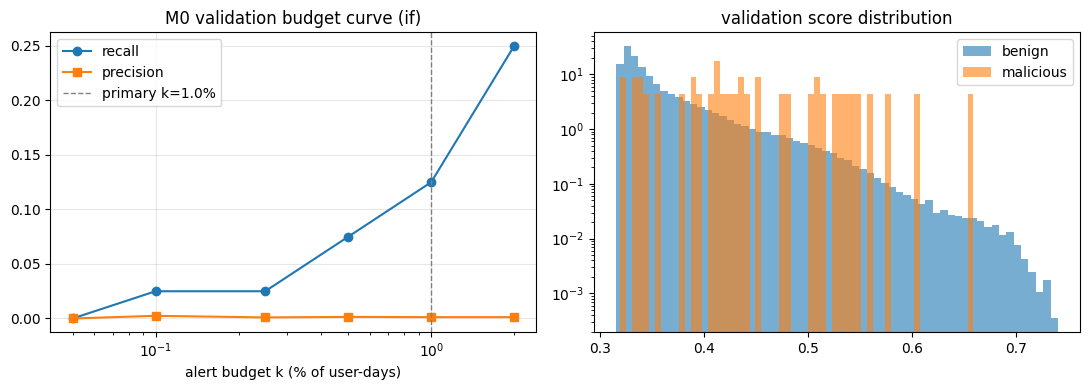

In [5]:
# ============================================================
# 4. Validation: detector choice (V1) + FIXED primary budget
#    (V2-amended — see markdown above; test data NOT touched here)
# ============================================================
from sklearn.metrics import roc_auc_score, average_precision_score

K_GRID = [0.05, 0.1, 0.25, 0.5, 1.0, 2.0]   # % of user-days (full curve reported)
K_PRIMARY = 1.0                              # fixed primary budget (V2-amended)
DETECTORS = ["if", "ae", "ens"]

yv = scores.loc[MASK["val"], "label"].to_numpy()
val_rows, grids = [], {}
for det in DETECTORS:
    sv = scores.loc[MASK["val"], f"score_{det}"].to_numpy()
    g = mu.budget_grid(yv, sv, K_GRID)
    g.insert(0, "detector", det)
    grids[det] = g
    val_rows.append({"detector": det,
                     "roc_auc": roc_auc_score(yv, sv),
                     "pr_auc":  average_precision_score(yv, sv)})
val_tbl = pd.DataFrame(val_rows).sort_values("pr_auc", ascending=False)
print("validation, threshold-free:")
print(val_tbl.to_string(index=False))

BEST_DET = str(val_tbl.iloc[0]["detector"])          # rule V1 (unchanged)
BEST_K = K_PRIMARY                                   # rule V2-amended (fixed)

pd.concat(grids.values(), ignore_index=True).to_csv(
    f"{WORK}/m0_validation_grid.csv", index=False)
print(f"\nchosen detector (V1): {BEST_DET} | primary budget (V2-amended): "
      f"k = {BEST_K}% of user-days")
print("\nfull validation budget grid for chosen detector:")
print(grids[BEST_DET].to_string(index=False))

sv = scores.loc[MASK["val"], f"score_{BEST_DET}"].to_numpy()
val_alert = mu.alerts_at_budget(sv, BEST_K)
POLICY = {
    "detector": BEST_DET,
    "k_pct": BEST_K,
    "score_threshold_at_val_budget": float(sv[val_alert].min()),
    "k_grid": K_GRID,
    "selection_rules": (
        "V1: detector family = argmax validation PR-AUC over {if, ae, ens}. "
        "V2-AMENDED: primary alert budget FIXED a priori at k=1.0% of user-days "
        "(realistic SOC triage budget). The full pre-specified k grid must be "
        "reported for every configuration in Notebook 5; the SAME detector family "
        "and k apply identically to all of M0-M3."),
    "v2_amendment": (
        "Original V2 (argmax validation F1 on the grid, ties -> smaller k) was "
        "found DEGENERATE on M0 validation data (4 Jul 2026): under ~10,000:1 "
        "imbalance F1 is precision-dominated and mechanically selects the smallest "
        "budget (k=0.05%, validation recall 2.5%), leaving near-zero statistical "
        "power for the cross-model recall comparison. Amended to a fixed k=1.0% "
        "BEFORE Notebook 5 was built and before any cross-model comparison was "
        "run. Secondary analysis pre-specified for NB5: account-level detection "
        "(insider account flagged at least once within the evaluation window)."),
    "seed": SEED,
    "validation_threshold_free": val_tbl.to_dict("records"),
}
with open(f"{WORK}/threshold_policy.json", "w") as fh:
    json.dump(POLICY, fh, indent=2)
print("\nthreshold_policy.json FROZEN (validation data only; V2 amendment recorded).")

# --- figures for Ch.4/5 ---
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
g = grids[BEST_DET]
ax[0].plot(g["k_pct"], g["recall"], "o-", label="recall")
ax[0].plot(g["k_pct"], g["precision"], "s-", label="precision")
ax[0].axvline(K_PRIMARY, color="grey", ls="--", lw=1, label=f"primary k={K_PRIMARY}%")
ax[0].set_xscale("log")
ax[0].set_xlabel("alert budget k (% of user-days)")
ax[0].set_title(f"M0 validation budget curve ({BEST_DET})")
ax[0].legend(); ax[0].grid(alpha=.3)
b = scores.loc[MASK["val"]]
ax[1].hist(b.loc[b.label == 0, f"score_{BEST_DET}"], bins=60,
           alpha=.6, label="benign", density=True)
ax[1].hist(b.loc[b.label == 1, f"score_{BEST_DET}"], bins=60,
           alpha=.6, label="malicious", density=True)
ax[1].set_yscale("log")
ax[1].set_title("validation score distribution")
ax[1].legend()
plt.tight_layout()
plt.savefig(f"{WORK}/fig_m0_validation.png", dpi=150)
plt.show()

## 5. Evaluate the baseline on the test window

Apply the selected detector and common alert budget to the saved test scores. Report the confusion counts, operating-point metrics, ranking metrics and 95% confidence intervals.

The bootstrap samples users with replacement within positive-account and benign-account strata. Alert decisions remain fixed for the count-based intervals, using 1,000 replicates. Ranking intervals use 200 replicates.

Only two malicious accounts contribute the positive test days. The resulting recall interval reflects those observed clusters; additional bootstrap draws do not add independent insider examples.

This is the recorded baseline test evaluation, not evidence of a previously untouched test partition.


In [6]:
# ============================================================
# 5. TEST evaluation — once, at the frozen policy, with
#    cluster-by-user bootstrap CIs
# ============================================================
yt = scores.loc[MASK["test"], "label"].to_numpy()
ut = scores.loc[MASK["test"], "user"].to_numpy()
st = scores.loc[MASK["test"], f"score_{BEST_DET}"].to_numpy()

alert = mu.alerts_at_budget(st, BEST_K)
point = mu.metrics_from_counts(*mu.counts(yt, alert))
point["roc_auc"] = roc_auc_score(yt, st)
point["pr_auc"]  = average_precision_score(yt, st)

t = time.time()
ci_cnt = mu.cluster_bootstrap_counts(ut, yt, alert, n_boot=1000, seed=SEED)
ci_auc = mu.cluster_bootstrap_auc(ut, yt, st, n_boot=200, seed=SEED)
print(f"bootstrap done in {time.time()-t:,.0f}s "
      f"(1000 resamples count metrics, 200 resamples AUCs, cluster = user)")

rows = []
for m in ("precision", "recall", "fpr", "f1"):
    lo, hi = ci_cnt[m]
    rows.append({"metric": m, "point": point[m], "ci95_lo": lo, "ci95_hi": hi})
for m in ("roc_auc", "pr_auc"):
    lo, hi = ci_auc[m]
    rows.append({"metric": m, "point": point[m], "ci95_lo": lo, "ci95_hi": hi})
test_tbl = pd.DataFrame(rows)
test_tbl.to_csv(f"{WORK}/m0_test_metrics.csv", index=False)

n_pos_users = int(pd.Series(ut)[yt.astype(bool)].nunique())
print(f"\nTEST @ detector={BEST_DET}, k={BEST_K}%: {int(alert.sum()):,} alerts | "
      f"TP {point['tp']} / FP {point['fp']} / FN {point['fn']} / TN {point['tn']:,}")
print(test_tbl.to_string(index=False))
print(f"\nNOTE for Ch.5: the recall CI is a cluster bootstrap over only "
      f"{n_pos_users} malicious account(s) present in the test window — the "
      f"interval is necessarily coarse and must be reported as such.")

bootstrap done in 36s (1000 resamples count metrics, 200 resamples AUCs, cluster = user)

TEST @ detector=if, k=1.0%: 3,955 alerts | TP 5 / FP 3950 / FN 33 / TN 391,561
   metric    point  ci95_lo  ci95_hi
precision 0.001264 0.000000 0.002865
   recall 0.131579 0.000000 0.555556
      fpr 0.009987 0.008237 0.012046
       f1 0.002504 0.000000 0.005700
  roc_auc 0.932889 0.921115 0.959946
   pr_auc 0.001026 0.000887 0.004062

NOTE for Ch.5: the recall CI is a cluster bootstrap over only 2 malicious account(s) present in the test window — the interval is necessarily coarse and must be reported as such.


## 6. Review the saved policy and output files

The final audit checks that outcome fields are absent from the feature list, reports the imported split and training-row count, and lists the saved artefacts.

Some printed messages use the older phrases "evaluation only" and "test partition read only in Section 5". Those messages are preserved as part of the code and execution record. Read them with the qualifications above: labels also support checks and selection, and the study had an earlier baseline-only test preview.


In [7]:
# ============================================================
# 6. Integrity audit + outputs (screenshot for §3.10 / Ch.4)
# ============================================================
print("M0 INTEGRITY AUDIT")
print("-" * 62)
print(f"1. Label column '{LABEL_COL}' used for EVALUATION ONLY.")
print(f"   '{LABEL_COL}' in FEATURES: {LABEL_COL in FEATURES} (must be False)")
assert LABEL_COL not in FEATURES
assert "user_is_insider" not in FEATURES
print(f"2. Split IMPORTED from NB3, never recomputed: {s_hits[0]}")
print(f"3. Scaler + IsolationForest + autoencoder fitted on the train "
      f"partition only: {N_TRAIN_FIT:,} rows "
      f"(= current train mask sum {int(MASK['train'].sum()):,})")
print(f"4. Threshold policy frozen on VALIDATION before test evaluation:")
print(f"   detector={POLICY['detector']}, k={POLICY['k_pct']}% "
      f"(rule V1 + amended V2 — amendment recorded in threshold_policy.json)")
print(f"5. Test partition read only in Section 5 (a single evaluation pass).")
print(f"6. SEED={SEED} for numpy/random/IsolationForest/MLP/bootstraps.")
print("-" * 62)
print(f"\ntotal runtime: {(time.time() - T0) / 60:.1f} min")
print("\nfiles in /kaggle/working:")
for f in sorted(os.listdir(WORK)):
    p = f"{WORK}/{f}"
    if os.path.isfile(p):
        print(f"  {f:38s} {os.path.getsize(p)/1e6:8,.1f} MB")

M0 INTEGRITY AUDIT
--------------------------------------------------------------
1. Label column 'label' used for EVALUATION ONLY.
   'label' in FEATURES: False (must be False)
2. Split IMPORTED from NB3, never recomputed: /kaggle/input/notebooks/thandondhlovu10/3-synthetic-organisational-bi/split_definition.json
3. Scaler + IsolationForest + autoencoder fitted on the train partition only: 592,378 rows (= current train mask sum 592,378)
4. Threshold policy frozen on VALIDATION before test evaluation:
   detector=if, k=1.0% (rule V1 + amended V2 — amendment recorded in threshold_policy.json)
5. Test partition read only in Section 5 (a single evaluation pass).
6. SEED=42 for numpy/random/IsolationForest/MLP/bootstraps.
--------------------------------------------------------------

total runtime: 2.4 min

files in /kaggle/working:
  __notebook__.ipynb                          0.1 MB
  fig_m0_validation.png                       0.1 MB
  m0_autoencoder.joblib                       0.0 MB